# 5 · Caso Gama (Parte 2) — risco ponderado por probabilidades e taxa ajustada

Na Parte 1 a Empresa Gama escolheu os dois melhores projetos: **P2 e P4** (os de maior RAU, critério
coerente com a hipótese de repetição; P4 também é o campeão da análise marginal). A Parte 2 pede a avaliação
desses dois projetos **levando em conta o risco econômico**, com uma estrutura clássica das notas de Análise de
Risco:

* para cada projeto, uma **variável crítica** (CPV em P2, preço de venda em P4) com três hipóteses —
  pessimista (10%), mais provável (85%) e otimista (5%);
* dentro das hipóteses extremas, **quatro alternativas** com probabilidades condicionais (70 / 15 / 10 / 5% no
  ramo pessimista; 60 / 20 / 15 / 5% no otimista);
* uma **curva de indiferença** que converte o coeficiente de variação do VPL numa taxa de desconto ajustada ao
  risco.

Não há simulação aqui: o risco é **ponderado pelas probabilidades** da árvore (valor esperado, desvio padrão e
CV calculados exatamente, como nas notas), e a pergunta final é: *qual seria, nesta situação, a decisão final?*

| Projeto | Variável | Pessimista (10%) | Mais provável (85%) | Otimista (5%) |
|---|---|---|---|---|
| P2 | Custo dos produtos vendidos | +2% (70%), +5% (15%), +7% (10%), +10% (5%) | enunciado | −2% (60%), −5% (20%), −8% (15%), −10% (5%) |
| P4 | Preço de venda | −2% (70%), −3% (15%), −4% (10%), −5% (5%) | enunciado | +1% (60%), +2% (20%), +3% (15%), +4% (5%) |

In [1]:
import numpy as np
import pandas as pd

from greenseer import *
from greenseer import viz
from caso_gama import BASE, K, MODELOS, CURVA_INDIFERENCA, arvore_p2, arvore_p4

viz.configurar_notebook()
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
SAIDA = "../outputs/05"

# ponto de partida: os dois projetos escolhidos, no caso-base
modelos = {"P2": MODELOS["P2"], "P4": MODELOS["P4"]}
estilizar(tabela_indicadores([modelos[p](BASE) for p in modelos], K)[["investimento", "vida", "vpl", "tir", "rau", "ibc", "payback_descontado"]], titulo="Caso-base (Parte 1): P2 e P4 à TMA de 18%")

,Investimento,Vida (anos),VPL,TIR,RAU,IBC,Payback ajustado
Projeto,,,,,,,
P2,$ 200.000,5,$ 30.609,"25,46%",$ 9.788,"1,15","3,66 anos"
P4,$ 300.000,6,$ 42.350,"23,82%",$ 12.108,"1,14","4,76 anos"


## 1. Modelar a árvore de probabilidades

A biblioteca descreve a árvore com três objetos:

* `Hipotese(nome, probabilidade, alternativas=[...])` — ramo de primeiro nível;
* `Cenario(nome, probabilidade=p_condicional, variacoes={parametro: ±fração})` — alternativa dentro da hipótese.
  `variacoes` multiplica o valor-base por (1 + fração): "CPV 2% maior" vira `{"p2_cpv": +0.02}`;
* `ArvoreDeCenarios([...])` — valida que as probabilidades somam 1 em cada nível e **expande** a árvore nas
  folhas, com a probabilidade conjunta P(hipótese) × P(alternativa | hipótese).

O mesmo modelo parametrizado dos notebooks 3 e 4 (`caso_gama.py`) é reavaliado em cada folha. Abaixo, a árvore
do P2 escrita por extenso (a do P4 segue o mesmo padrão e está em `caso_gama.arvore_p4`).

In [2]:
def alternativa(nome, variacao, prob):
    return Cenario(nome, probabilidade=prob, variacoes={"p2_cpv": variacao})

arvore_cpv = ArvoreDeCenarios(
    [
        Hipotese("Pessimista", 0.10, [alternativa("CPV +2%", 0.02, 0.70), alternativa("CPV +5%", 0.05, 0.15), alternativa("CPV +7%", 0.07, 0.10), alternativa("CPV +10%", 0.10, 0.05)]),
        Hipotese("Mais provável", 0.85),
        Hipotese("Otimista", 0.05, [alternativa("CPV −2%", -0.02, 0.60), alternativa("CPV −5%", -0.05, 0.20), alternativa("CPV −8%", -0.08, 0.15), alternativa("CPV −10%", -0.10, 0.05)]),
    ],
    nome="P2 · CPV", parametro="p2_cpv",
)
arvore_preco = arvore_p4()
tab = arvore_cpv.tabela()
estilizar(tab, tipos={"P(hipótese)": "pct", "P(alt | hip)": "pct", "P conjunta": "pct"}, destacar=[], titulo="P2 — folhas da árvore e probabilidades conjuntas (somam 100%)")

,Hipótese,P(hipótese),Alternativa,P(alt | hip),P conjunta,Alteração,Cenário
0,Pessimista,"10,00%",CPV +2%,"70,00%","7,00%",p2_cpv +2.0%,Pessimista · CPV +2%
1,Pessimista,"10,00%",CPV +5%,"15,00%","1,50%",p2_cpv +5.0%,Pessimista · CPV +5%
2,Pessimista,"10,00%",CPV +7%,"10,00%","1,00%",p2_cpv +7.0%,Pessimista · CPV +7%
3,Pessimista,"10,00%",CPV +10%,"5,00%","0,50%",p2_cpv +10.0%,Pessimista · CPV +10%
4,Mais provável,"85,00%",—,"100,00%","85,00%",caso-base,Mais provável
5,Otimista,"5,00%",CPV −2%,"60,00%","3,00%",p2_cpv -2.0%,Otimista · CPV −2%
6,Otimista,"5,00%",CPV −5%,"20,00%","1,00%",p2_cpv -5.0%,Otimista · CPV −5%
7,Otimista,"5,00%",CPV −8%,"15,00%","0,75%",p2_cpv -8.0%,Otimista · CPV −8%
8,Otimista,"5,00%",CPV −10%,"5,00%","0,25%",p2_cpv -10.0%,Otimista · CPV −10%


**Uma escolha de interpretação.** "Acréscimo de 2% no CPV" foi lido como variação *relativa* do percentual
(60% → 61,2% da receita). A leitura alternativa, 2 pontos percentuais (60% → 62%), é mais severa; a seção 6
mostra que ela não muda a decisão. Para o preço do P4 não há ambiguidade.

Os valores que a variável assume em cada folha, com as probabilidades, formam uma distribuição discreta:

In [3]:
valores, probs = arvore_cpv.como_distribuicao(BASE, "p2_cpv")
pd.DataFrame({"CPV (% da receita)": valores, "Probabilidade": probs}, index=[c.nome for c in arvore_cpv.expandir()]).style.format({"CPV (% da receita)": "{:.2%}", "Probabilidade": "{:.2%}"})

,CPV (% da receita),Probabilidade
Pessimista · CPV +2%,61.20%,7.00%
Pessimista · CPV +5%,63.00%,1.50%
Pessimista · CPV +7%,64.20%,1.00%
Pessimista · CPV +10%,66.00%,0.50%
Mais provável,60.00%,85.00%
Otimista · CPV −2%,58.80%,3.00%
Otimista · CPV −5%,57.00%,1.00%
Otimista · CPV −8%,55.20%,0.75%
Otimista · CPV −10%,54.00%,0.25%


## 2. VPL em cada folha

`AnaliseDeCenarios` aceita uma árvore por projeto (`{"P2": árvore_cpv, "P4": árvore_preco}`): cada modelo é
avaliado nas suas próprias folhas, todas à TMA de 18%.

In [4]:
ac = AnaliseDeCenarios(modelos, BASE, {"P2": arvore_cpv, "P4": arvore_preco}, taxa=K)
resultado = ac.executar()
estilizar(resultado[["Projeto", "Hipótese", "Cenário", "Probabilidade", "vpl", "tir", "rau", "payback_descontado"]], tipos={"Probabilidade": "pct"}, destacar=[], titulo="VPL, TIR, RAU e payback em cada folha (TMA 18%)")

,Projeto,Hipótese,Cenário,Probabilidade,VPL,TIR,RAU,Payback ajustado
0,P2,Pessimista,Pessimista · CPV +2%,"7,00%",$ 15.330,"21,79%",$ 4.902,"4,24 anos"
1,P2,Pessimista,Pessimista · CPV +5%,"1,50%",($ 7.588),"16,08%",($ 2.426),—
2,P2,Pessimista,Pessimista · CPV +7%,"1,00%",($ 22.866),"12,12%",($ 7.312),—
3,P2,Pessimista,Pessimista · CPV +10%,"0,50%",($ 45.784),"5,87%",($ 14.641),—
4,P2,Mais provável,Mais provável,"85,00%",$ 30.609,"25,46%",$ 9.788,"3,66 anos"
5,P2,Otimista,Otimista · CPV −2%,"3,00%",$ 45.888,"29,04%",$ 14.674,"3,20 anos"
6,P2,Otimista,Otimista · CPV −5%,"1,00%",$ 68.806,"34,28%",$ 22.003,"2,78 anos"
7,P2,Otimista,Otimista · CPV −8%,"0,75%",$ 91.724,"39,37%",$ 29.331,"2,50 anos"
8,P2,Otimista,Otimista · CPV −10%,"0,25%",$ 107.003,"42,71%",$ 34.217,"2,34 anos"
9,P4,Pessimista,Pessimista · preço −2%,"7,00%",($ 6.057),"17,09%",($ 1.732),—


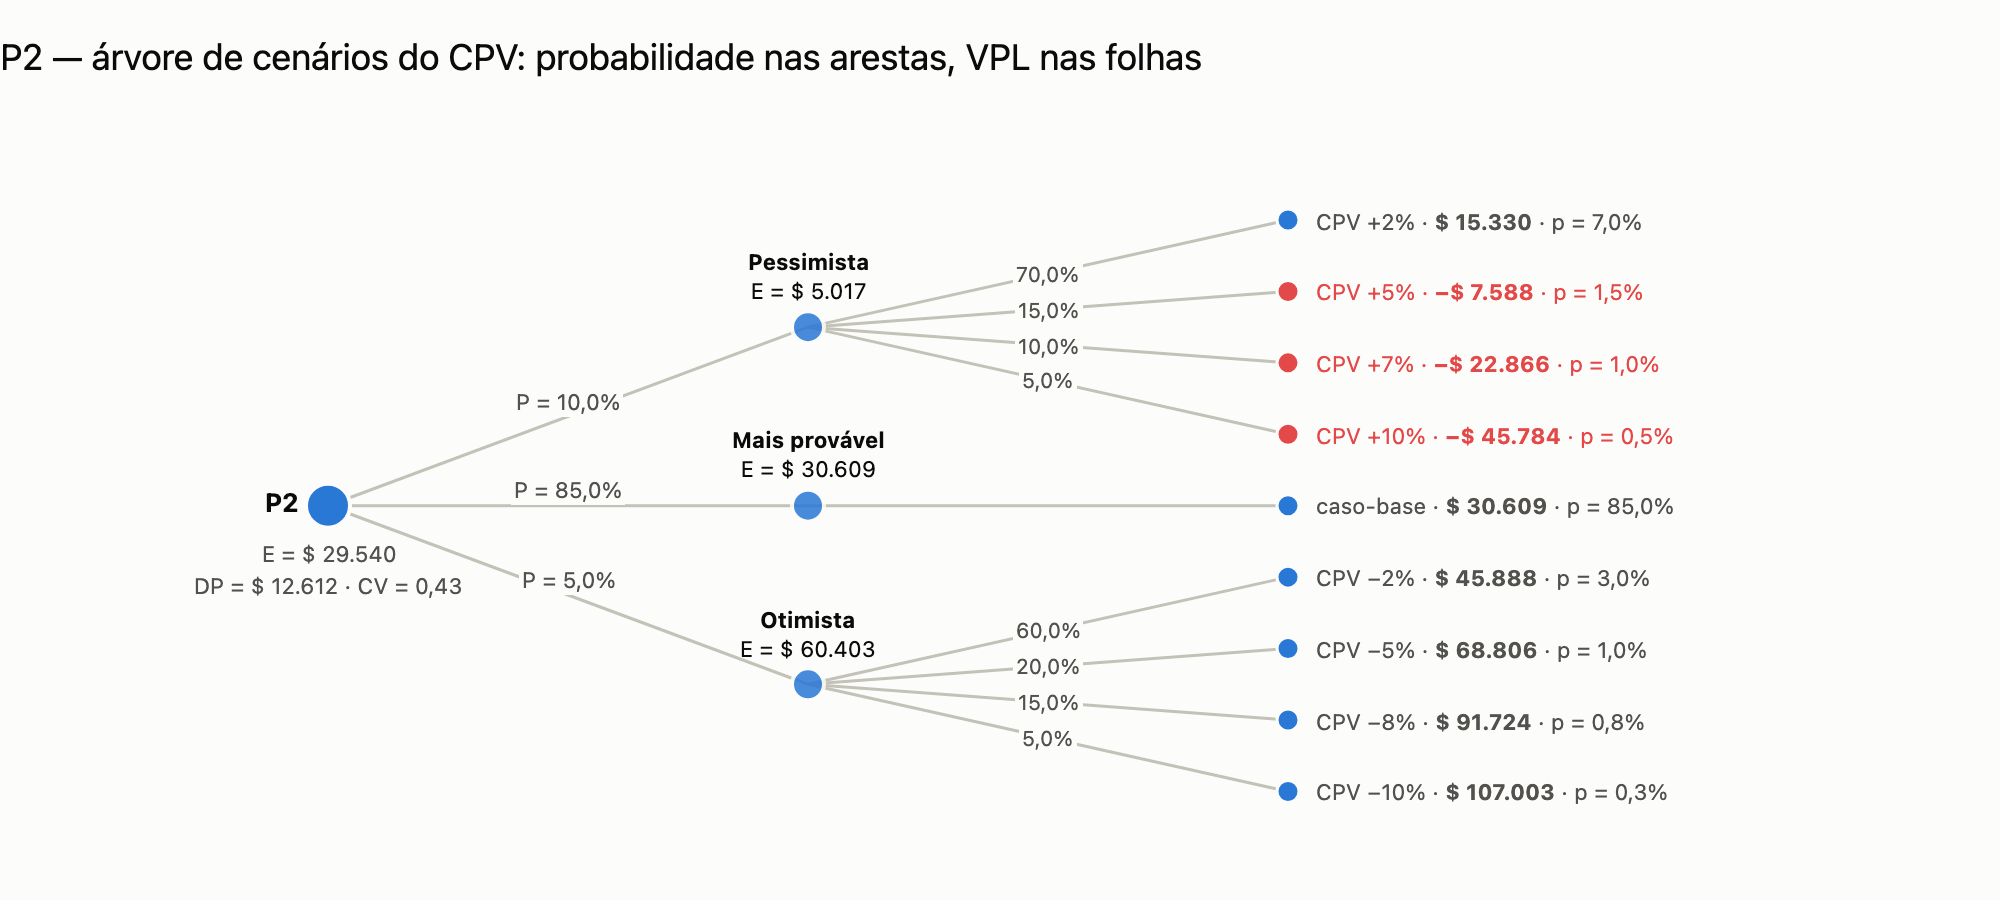

In [5]:
fig = viz.grafico_arvore(ac, "P2", titulo="P2 — árvore de cenários do CPV: probabilidade nas arestas, VPL nas folhas")
viz.exportar(fig, f"{SAIDA}/arvore_p2")
fig

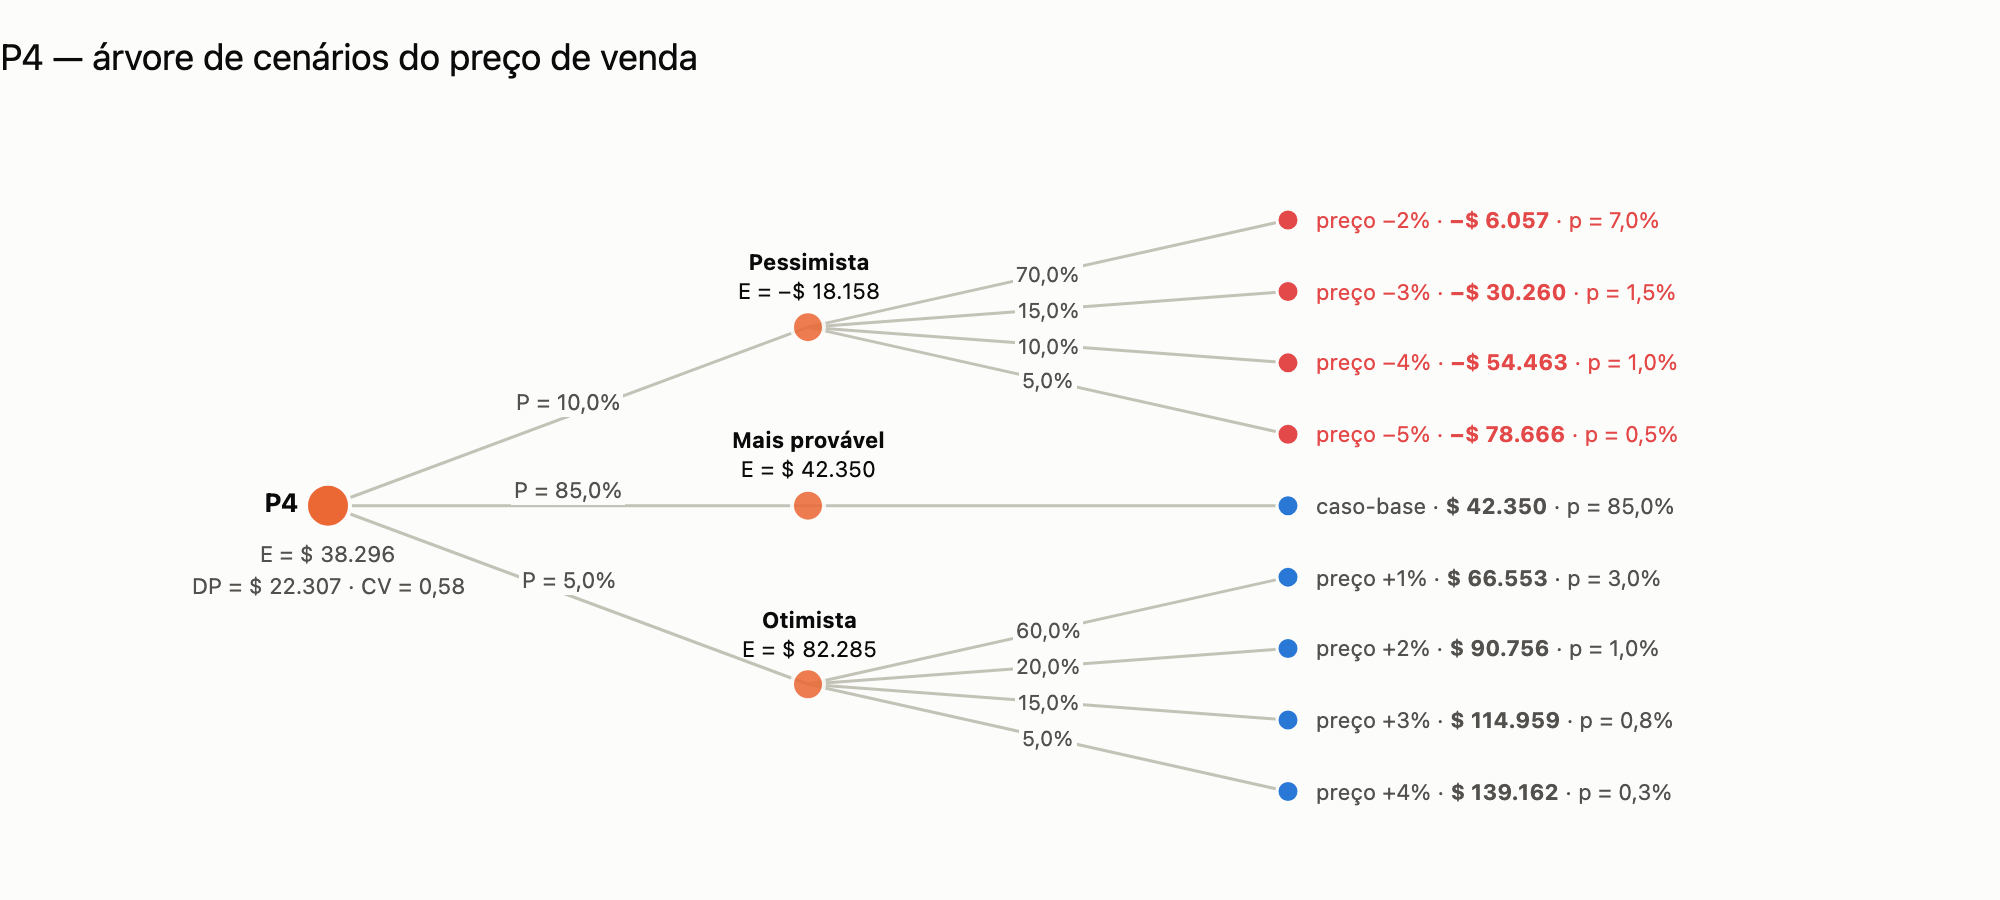

In [6]:
fig = viz.grafico_arvore(ac, "P4", titulo="P4 — árvore de cenários do preço de venda")
viz.exportar(fig, f"{SAIDA}/arvore_p4")
fig

## 3. Valor esperado, desvio padrão e coeficiente de variação

Exatamente como nas notas: E = Σ pᵢ·VPLᵢ, DP = √Σ pᵢ·(VPLᵢ − E)², CV = DP / E. A tabela de dispersão reproduz
o quadro de cálculo do curso, folha a folha.

In [7]:
td2 = ac.tabela_dispersao("P2")
estilizar(td2, tipos={"pi": "pct", "Ei": "moeda", "pi · Ei": "moeda", "Ei − E": "moeda", "(Ei − E)²": "num", "pi · (Ei − E)²": "num"}, destacar=[], titulo=f"P2 — E = {fmt_moeda(td2.attrs['valor_esperado'])} · DP = {fmt_moeda(td2.attrs['desvio_padrao'])} · CV = {td2.attrs['cv']:.2f}")

,Cenário,pi,Ei,pi · Ei,Ei − E,(Ei − E)²,pi · (Ei − E)²
0,Pessimista · CPV +2%,"7,00%",$ 15.330,$ 1.073,($ 14.209),"201.900.771,82","14.133.054,03"
1,Pessimista · CPV +5%,"1,50%",($ 7.588),($ 114),($ 37.127),"1.378.429.723,12","20.676.445,85"
2,Pessimista · CPV +7%,"1,00%",($ 22.866),($ 229),($ 52.406),"2.746.378.067,28","27.463.780,67"
3,Pessimista · CPV +10%,"0,50%",($ 45.784),($ 229),($ 75.324),"5.673.694.148,48","28.368.470,74"
4,Mais provável,"85,00%",$ 30.609,$ 26.018,$ 1.070,"1.143.847,59","972.270,45"
5,Otimista · CPV −2%,"3,00%",$ 45.888,$ 1.377,$ 16.348,"267.263.491,34","8.017.904,74"
6,Otimista · CPV −5%,"1,00%",$ 68.806,$ 688,$ 39.266,"1.541.836.521,91","15.418.365,22"
7,Otimista · CPV −8%,"0,75%",$ 91.724,$ 688,$ 62.184,"3.866.881.830,42","29.001.613,73"
8,Otimista · CPV −10%,"0,25%",$ 107.003,$ 268,$ 77.463,"6.000.507.746,06","15.001.269,37"
9,Total,"100,00%",—,$ 29.540,—,—,"159.053.174,79"


In [8]:
td4 = ac.tabela_dispersao("P4")
estilizar(td4, tipos={"pi": "pct", "Ei": "moeda", "pi · Ei": "moeda", "Ei − E": "moeda", "(Ei − E)²": "num", "pi · (Ei − E)²": "num"}, destacar=[], titulo=f"P4 — E = {fmt_moeda(td4.attrs['valor_esperado'])} · DP = {fmt_moeda(td4.attrs['desvio_padrao'])} · CV = {td4.attrs['cv']:.2f}")

,Cenário,pi,Ei,pi · Ei,Ei − E,(Ei − E)²,pi · (Ei − E)²
0,Pessimista · preço −2%,"7,00%",($ 6.057),($ 424),($ 44.352),"1.967.110.876,28","137.697.761,34"
1,Pessimista · preço −3%,"1,50%",($ 30.260),($ 454),($ 68.555),"4.699.814.426,98","70.497.216,40"
2,Pessimista · preço −4%,"1,00%",($ 54.463),($ 545),($ 92.758),"8.604.095.062,65","86.040.950,63"
3,Pessimista · preço −5%,"0,50%",($ 78.666),($ 393),($ 116.961),"13.679.952.783,30","68.399.763,92"
4,Mais provável,"85,00%",$ 42.350,$ 35.997,$ 4.054,"16.435.029,80","13.969.775,33"
5,Otimista · preço +1%,"3,00%",$ 66.553,$ 1.997,$ 28.257,"798.462.734,01","23.953.882,02"
6,Otimista · preço +2%,"1,00%",$ 90.756,$ 908,$ 52.460,"2.752.067.523,21","27.520.675,23"
7,Otimista · preço +3%,"0,75%",$ 114.959,$ 862,$ 76.663,"5.877.249.397,37","44.079.370,48"
8,Otimista · preço +4%,"0,25%",$ 139.162,$ 348,$ 100.866,"10.174.008.356,51","25.435.020,89"
9,Total,"100,00%",—,$ 38.296,—,—,"497.594.416,24"


In [9]:
resumo = ac.resumo("vpl")
estilizar(resumo, titulo="Resumo por projeto")

,Valor esperado,Desvio padrão,CV,Mínimo,Máximo,P(< 0)
Projeto,,,,,,
P2,$ 29.540,$ 12.612,"0,43",($ 45.784),$ 107.003,"3,00%"
P4,$ 38.296,$ 22.307,"0,58",($ 78.666),$ 139.162,"10,00%"


In [10]:
estilizar(ac.resumo_por_hipotese("vpl"), tipos={"P(hipótese)": "pct", "Nº alternativas": "int", "E[métrica | hipótese]": "moeda", "Mínimo": "moeda", "Máximo": "moeda", "Contribuição P × E": "moeda"}, destacar=[], titulo="Leitura por hipótese: valor esperado condicional e contribuição ao valor esperado")

,Projeto,Hipótese,P(hipótese),Nº alternativas,E[métrica | hipótese],Mínimo,Máximo,Contribuição P × E
0,P2,Pessimista,"10,00%",4,$ 5.017,($ 45.784),$ 15.330,$ 502
1,P2,Mais provável,"85,00%",1,$ 30.609,$ 30.609,$ 30.609,$ 26.018
2,P2,Otimista,"5,00%",4,$ 60.403,$ 45.888,$ 107.003,$ 3.020
3,P4,Pessimista,"10,00%",4,($ 18.158),($ 78.666),($ 6.057),($ 1.816)
4,P4,Mais provável,"85,00%",1,$ 42.350,$ 42.350,$ 42.350,$ 35.997
5,P4,Otimista,"5,00%",4,$ 82.285,$ 66.553,$ 139.162,$ 4.114


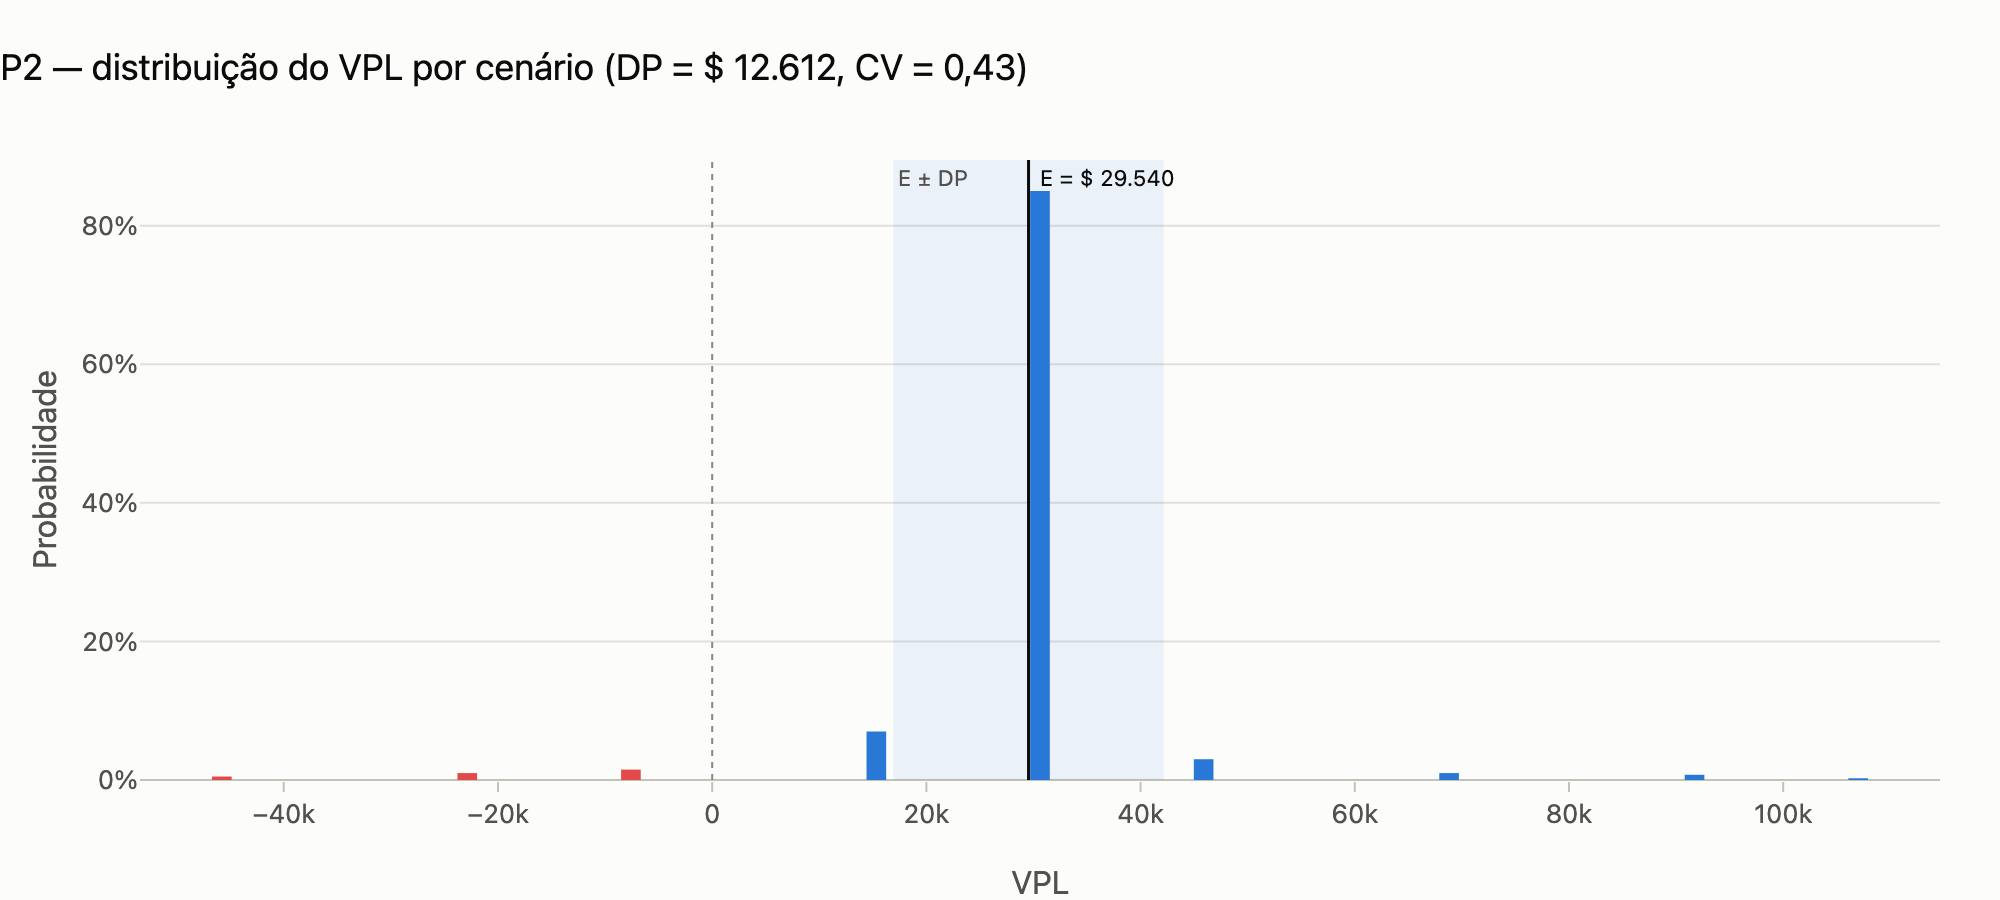

In [11]:
fig = viz.grafico_distribuicao_discreta(ac, "P2")
viz.exportar(fig, f"{SAIDA}/distribuicao_p2")
fig

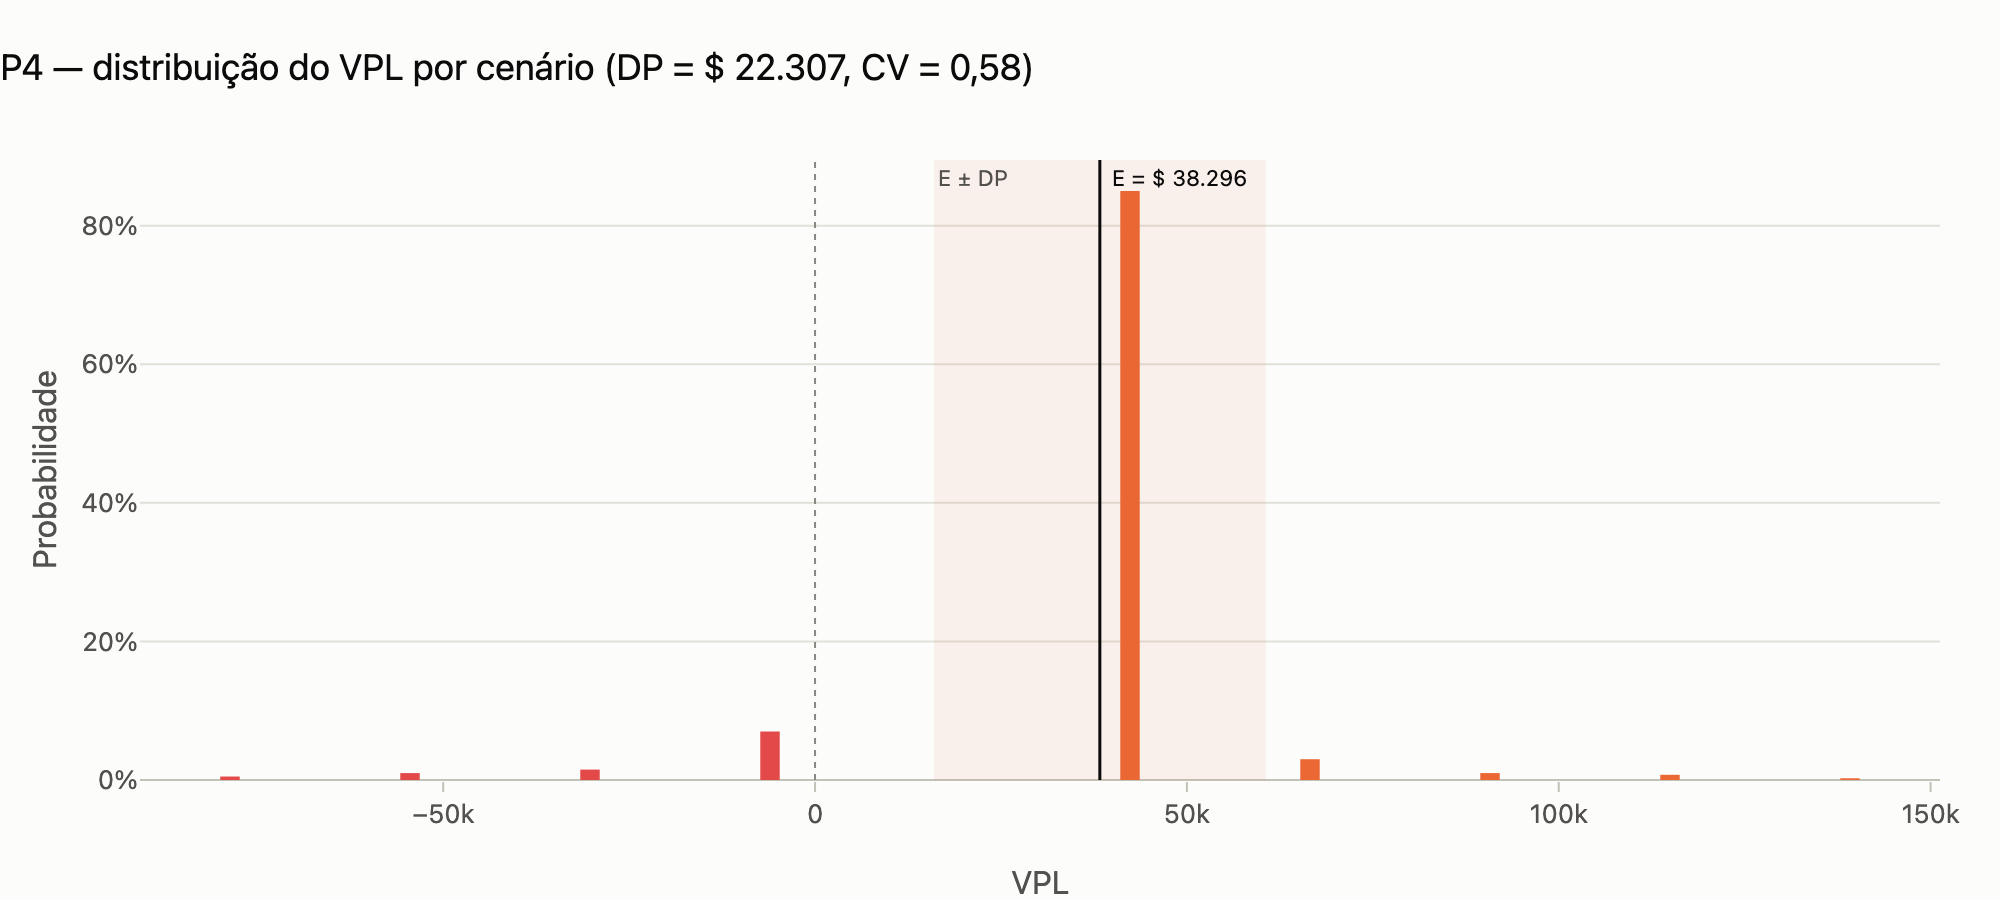

In [12]:
fig = viz.grafico_distribuicao_discreta(ac, "P4")
viz.exportar(fig, f"{SAIDA}/distribuicao_p4")
fig

**Leitura.** O ramo pessimista pesa mais que o otimista nos dois projetos (10% contra 5%), por isso o valor
esperado fica um pouco abaixo do VPL do caso-base. A diferença está na dispersão: uma queda de poucos por cento
no preço do P4 derruba o VPL muito mais do que o mesmo percentual no CPV do P2, porque o P4 opera com custo fixo
de $200.000 e margem estreita. O CV do P4 é, portanto, bem maior — e é o CV que a curva de indiferença traduz em
taxa.

## 4. Curva de indiferença → taxa ajustada ao risco

O gráfico do enunciado foi lido ponto a ponto: CV 0,1 → 18% (a própria TMA), 0,3 → 19%, 0,5 → 20%,
0,7 → 22%, 0,9 → 25%. Entre os pontos a taxa é interpolada linearmente; abaixo de 0,1 vale 18%.

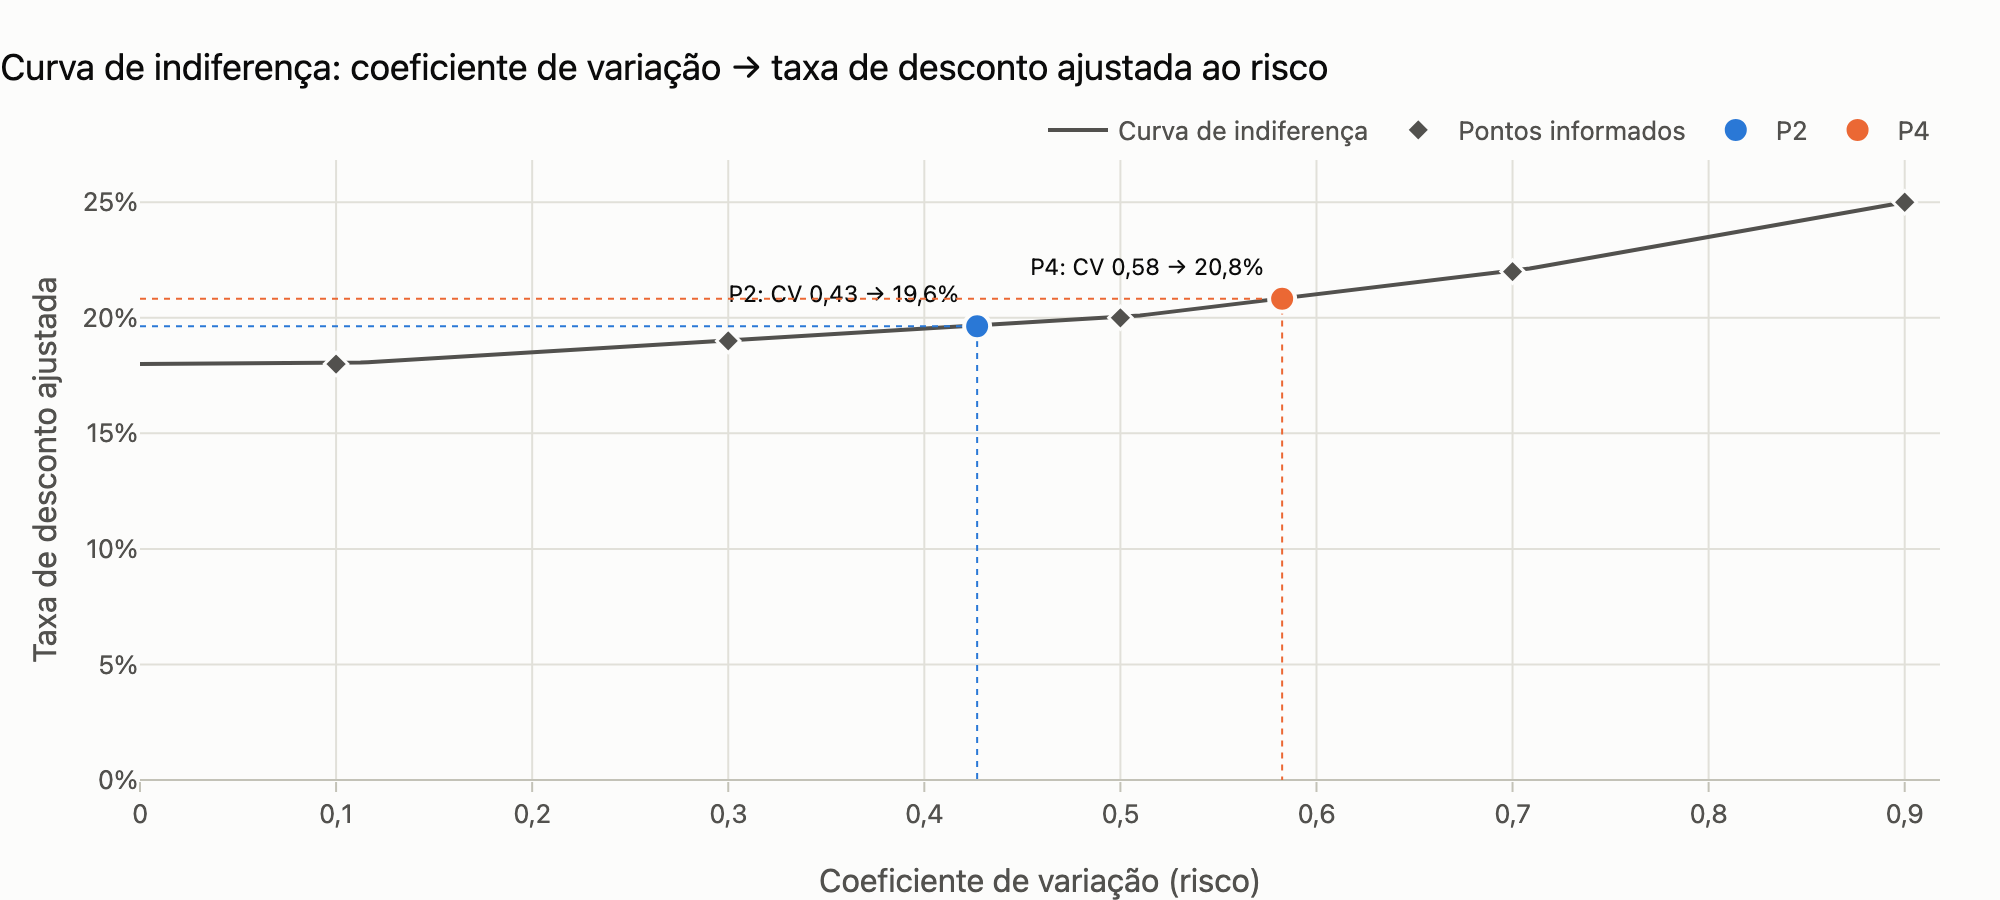

In [13]:
taxas = ac.taxas_ajustadas(CURVA_INDIFERENCA)
fig = viz.grafico_curva_indiferenca(CURVA_INDIFERENCA, resumo["CV"], extrapolar=False)
viz.exportar(fig, f"{SAIDA}/curva_indiferenca")
fig

## 5. Reavaliação à taxa ajustada e decisão

Cada projeto é descontado à sua taxa ajustada: VPL, RAU e IBC do caso-base recalculados. O projeto continua
aceitável se o VPL ajustado permanece positivo; entre os dois, o de maior RAU ajustado é o preferido.

In [14]:
avaliacao = ac.avaliacao_ajustada(CURVA_INDIFERENCA)
estilizar(avaliacao, tipos={"VPL à TMA": "moeda", "VPL ajustado": "moeda", "RAU ajustado": "moeda", "IBC ajustado": "num", "Taxa ajustada": "pct", "P(< 0)": "pct"}, destacar=["Valor esperado", "VPL ajustado", "RAU ajustado"], titulo="Avaliação ajustada ao risco")

,VPL à TMA,Valor esperado,Desvio padrão,CV,P(< 0),Taxa ajustada,VPL ajustado,RAU ajustado,IBC ajustado,TIR,Decisão
Projeto,,,,,,,,,,,
P2,$ 30.609,$ 29.540,$ 12.612,"0,43","3,00%","19,63%",$ 23.230,$ 7.705,"1,12","25,46%",aceitar
P4,$ 42.350,$ 38.296,$ 22.307,"0,58","10,00%","20,82%",$ 20.581,$ 6.316,"1,07","23,82%",aceitar


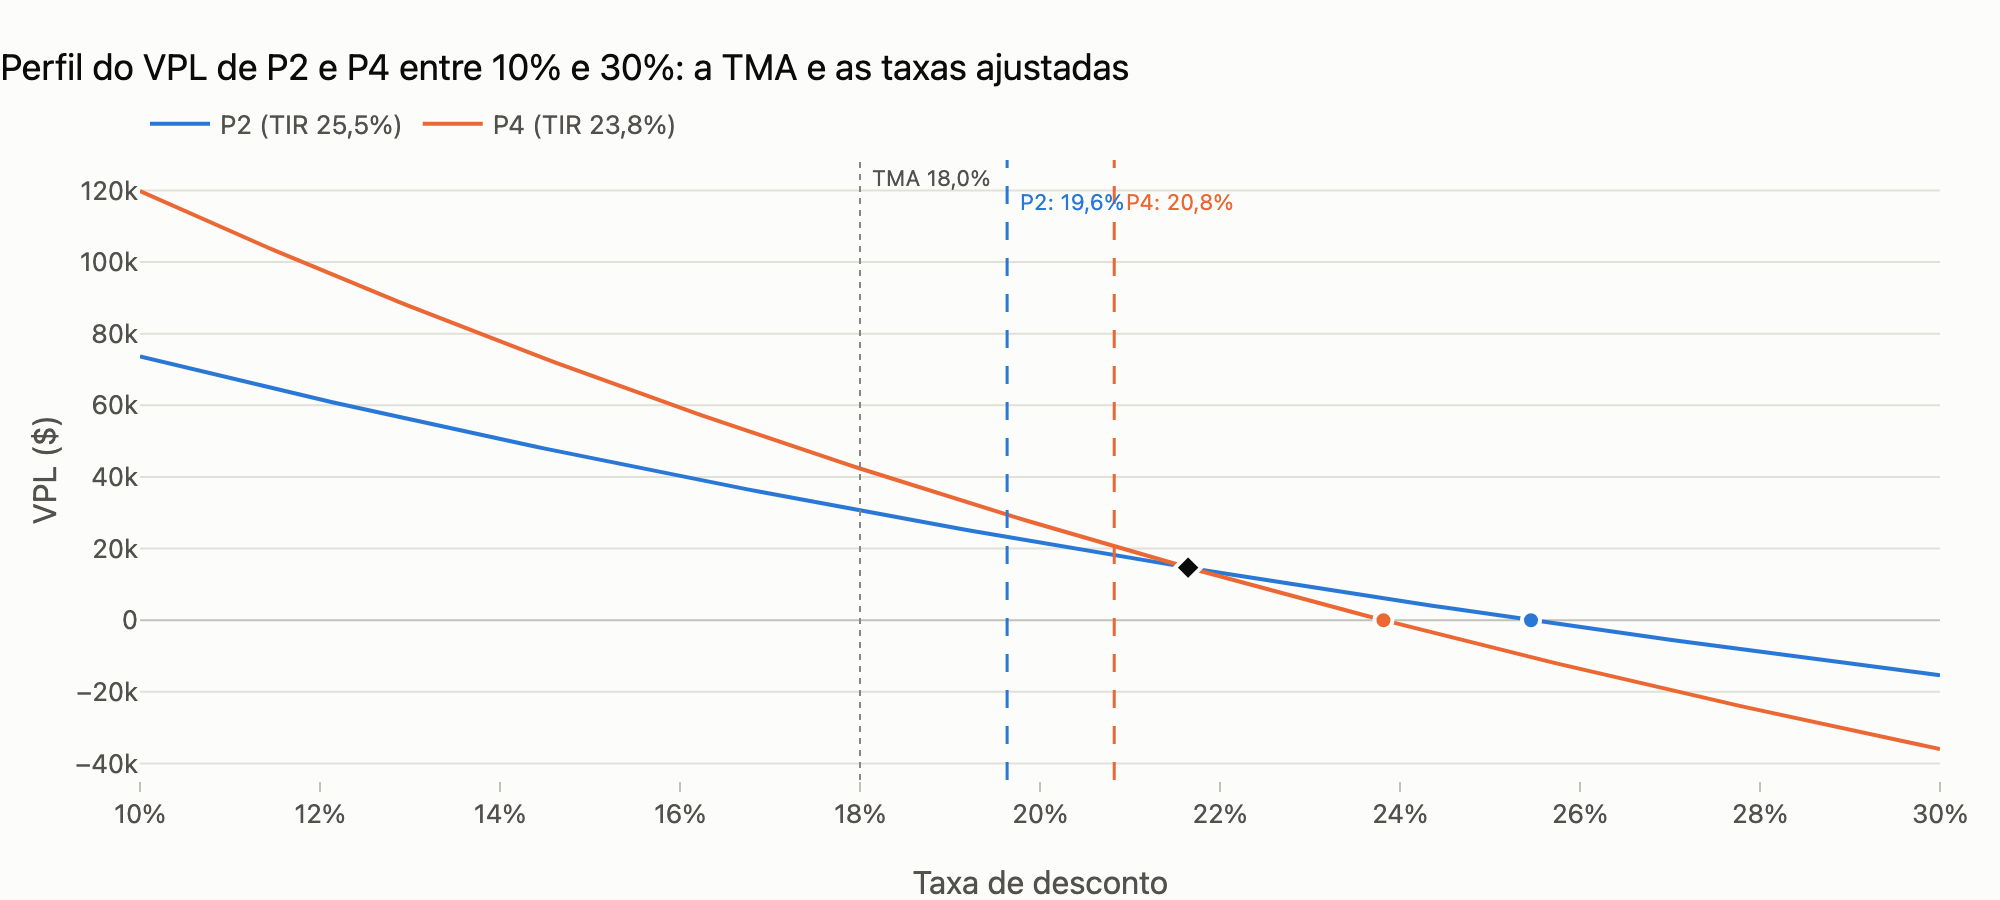

In [15]:
fluxos_base = [modelos[p](BASE).fluxo() for p in modelos]
fig = viz.grafico_perfil_vpl(fluxos_base, K, taxas=np.linspace(0.10, 0.30, 161), fisher=True, titulo="Perfil do VPL de P2 e P4 entre 10% e 30%: a TMA e as taxas ajustadas")
for p, tx in taxas.items():
    fig.add_vline(x=tx, line=dict(color=viz.cor_de(p), width=1.5, dash="dash"))
    fig.add_annotation(x=tx, y=0.96, yref="paper", text=f"{p}: {tx:.1%}".replace(".", ","), showarrow=False, xanchor="left", xshift=4, font=dict(size=11, color=viz.cor_de(p)))
viz.exportar(fig, f"{SAIDA}/perfil_ajustado")
fig

## 6. A decisão resiste às premissas?

Três verificações rápidas antes de fechar o parecer:

1. **Interpretação do CPV** (relativa × pontos percentuais);
2. **Peso do ramo pessimista**: e se a probabilidade da hipótese pessimista fosse maior que 10%?
3. **Extrapolação da curva** além de CV 0,9 (só importa se algum CV ultrapassar esse valor).

In [16]:
ac_pp = AnaliseDeCenarios({"P2": modelos["P2"]}, BASE, arvore_p2(modo="pp"), taxa=K)
ac_pp.executar()
comp = pd.concat({"CPV relativo (60% → 61,2%)": ac.avaliacao_ajustada(CURVA_INDIFERENCA).loc[["P2"]], "CPV em p.p. (60% → 62%)": ac_pp.avaliacao_ajustada(CURVA_INDIFERENCA)}, names=["Interpretação"])
estilizar(comp[["Valor esperado", "Desvio padrão", "CV", "Taxa ajustada", "VPL ajustado", "RAU ajustado", "Decisão"]], tipos={"Taxa ajustada": "pct", "VPL ajustado": "moeda", "RAU ajustado": "moeda"}, destacar=[], titulo="P2: as duas leituras do 'acréscimo de 2% no CPV'")

,,Valor esperado,Desvio padrão,CV,Taxa ajustada,VPL ajustado,RAU ajustado,Decisão
Interpretação,Projeto,,,,,,,
"CPV relativo (60% → 61,2%)",P2,$ 29.540,$ 12.612,"0,43","19,63%",$ 23.230,$ 7.705,aceitar
CPV em p.p. (60% → 62%),P2,$ 28.827,$ 21.019,"0,73","22,44%",$ 11.491,$ 4.050,aceitar


In [17]:
def com_peso_pessimista(arvore, p_pess):
    """Mesma árvore com outra probabilidade para a hipótese pessimista (o resto é redistribuído para a mais provável)."""
    hips = []
    for h in arvore.hipoteses:
        if h.nome == "Pessimista":
            hips.append(Hipotese(h.nome, p_pess, h.alternativas))
        elif h.nome == "Mais provável":
            hips.append(Hipotese(h.nome, 1.0 - p_pess - 0.05, h.alternativas))
        else:
            hips.append(h)
    return ArvoreDeCenarios(hips, nome=arvore.nome, parametro=arvore.parametro)

linhas = []
for p_pess in [0.10, 0.20, 0.30, 0.40, 0.50]:
    aci = AnaliseDeCenarios(modelos, BASE, {"P2": com_peso_pessimista(arvore_cpv, p_pess), "P4": com_peso_pessimista(arvore_preco, p_pess)}, taxa=K)
    aci.executar()
    av = aci.avaliacao_ajustada(CURVA_INDIFERENCA, extrapolar=True)
    for proj in modelos:
        linhas.append({"P(pessimista)": p_pess, "Projeto": proj, "Valor esperado": av.loc[proj, "Valor esperado"], "CV": av.loc[proj, "CV"], "Taxa ajustada": av.loc[proj, "Taxa ajustada"], "VPL ajustado": av.loc[proj, "VPL ajustado"], "RAU ajustado": av.loc[proj, "RAU ajustado"], "Decisão": av.loc[proj, "Decisão"]})
sens = pd.DataFrame(linhas)
sens["P(pessimista)"] = sens["P(pessimista)"].map(lambda v: f"{v:.0%}")
estilizar(sens.pivot(index="P(pessimista)", columns="Projeto", values="VPL ajustado"), tipos={"P2": "moeda", "P4": "moeda"}, destacar=[], titulo="VPL ajustado ao risco quando o ramo pessimista pesa mais (curva extrapolada além de CV 0,9)")

Projeto,P2,P4
P(pessimista),,
10%,$ 23.230,$ 20.581
20%,$ 18.308,($ 6.508)
30%,$ 11.711,($ 37.299)
40%,$ 2.669,($ 71.775)
50%,($ 6.690),($ 114.514)


In [18]:
estilizar(sens.pivot(index="P(pessimista)", columns="Projeto", values="Taxa ajustada"), tipos={"P2": "pct", "P4": "pct"}, destacar=[], titulo="Taxa ajustada correspondente")

Projeto,P2,P4
P(pessimista),,
10%,"19,63%","20,82%"
20%,"20,78%","24,84%"
30%,"22,38%","30,26%"
40%,"24,73%","37,84%"
50%,"27,36%","50,69%"


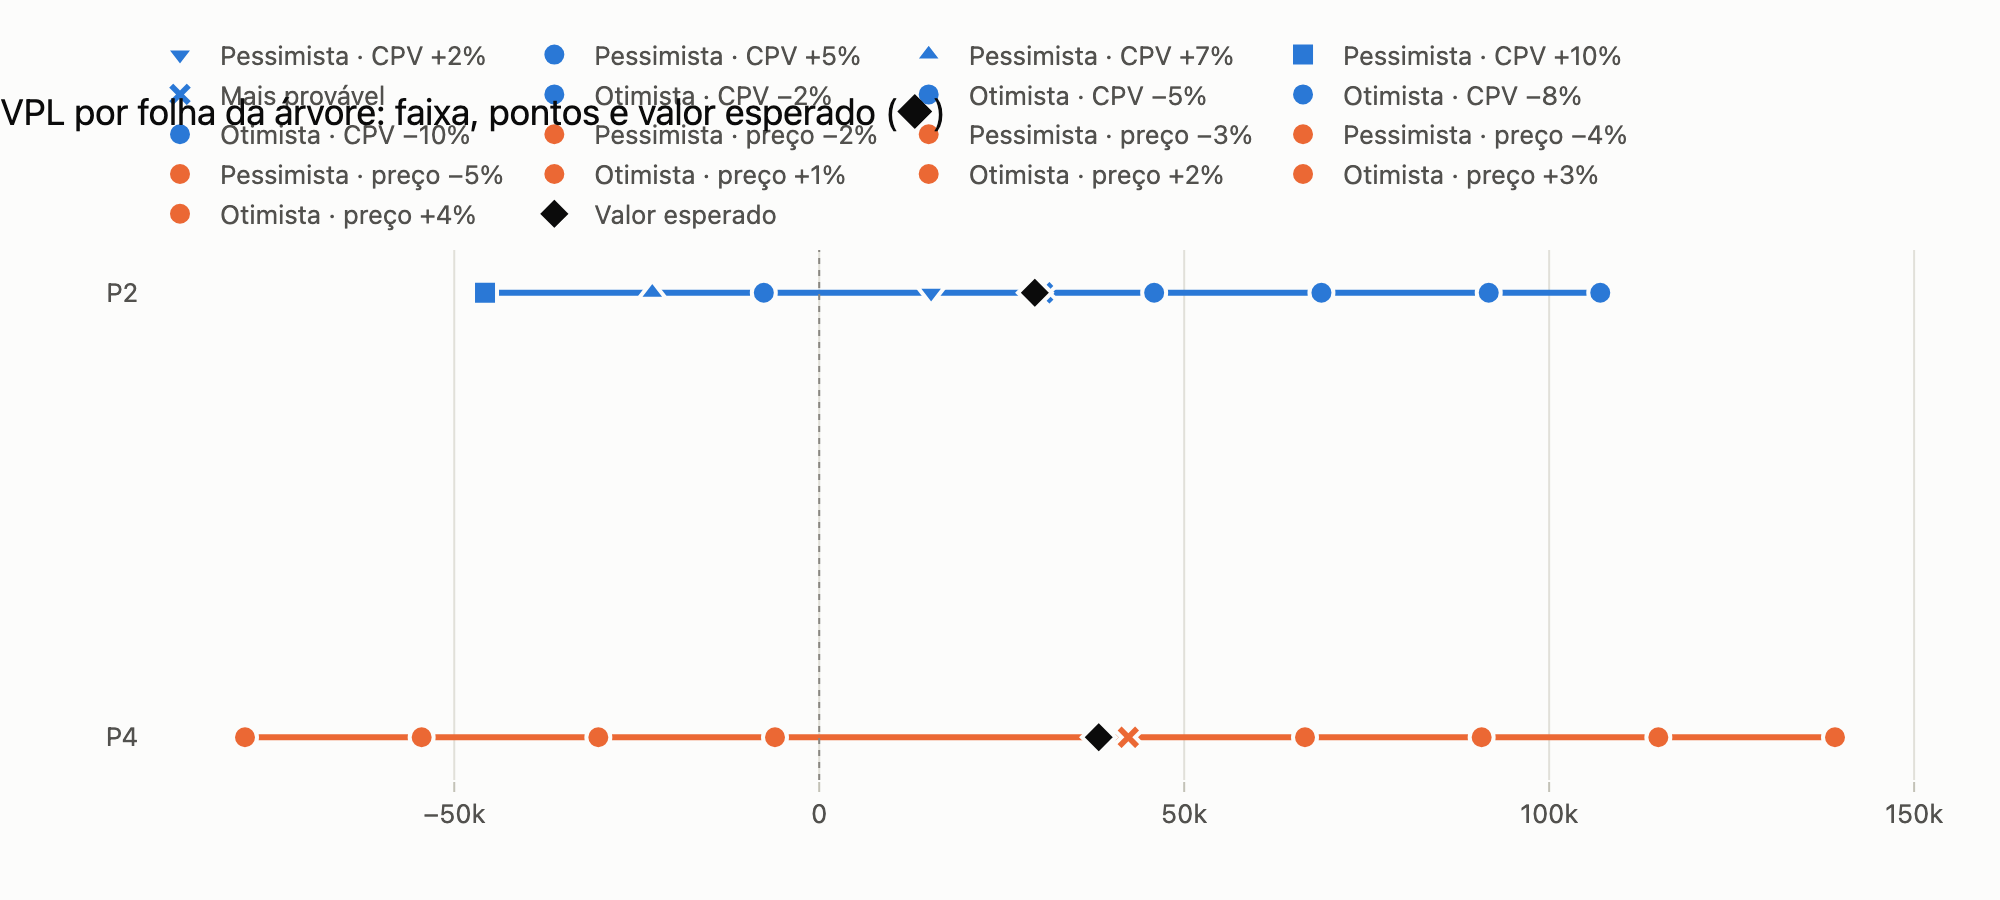

In [19]:
fig = viz.grafico_cenarios(resultado, "vpl", resumo, titulo="VPL por folha da árvore: faixa, pontos e valor esperado (◆)")
viz.exportar(fig, f"{SAIDA}/faixas")
fig

## 7. Parecer

| | P2 | P4 |
|---|---|---|
| VPL à TMA (18%) | $ 30.609 | $ 42.350 |
| Valor esperado do VPL | $ 29.540 | $ 38.296 |
| Desvio padrão · CV | $ 12.612 · 0,43 | $ 22.307 · 0,58 |
| Probabilidade de VPL negativo | 3% | 10% |
| Taxa ajustada ao risco | 19,6% | 20,8% |
| VPL à taxa ajustada | **$ 23.230** | $ 20.581 |
| RAU à taxa ajustada | **$ 7.705** | $ 6.316 |

* **Os dois projetos continuam aceitáveis**: VPL positivo mesmo descontados às taxas ajustadas ao risco.
* **A ordem de preferência se inverte.** No caso-base P4 lidera em VPL e RAU; ajustado ao risco, **P2 passa à
  frente** (VPL ajustado $ 23,2 mil contra $ 20,6 mil; RAU $ 7,7 mil contra $ 6,3 mil). O preço de venda é a
  variável à qual P4 é mais sensível, e todo o ramo pessimista do P4 produz VPL negativo.
* **Robustez.** A leitura em pontos percentuais do CPV piora P2 (CV 0,73, taxa 22,4%), mas ele continua aceito.
  Já o P4 é frágil ao peso do ramo pessimista: se a hipótese pessimista tivesse 20% em vez de 10%, o VPL
  ajustado do P4 ficaria negativo; P2 só cai abaixo de zero com 50%.

**Decisão final:** manter os dois projetos escolhidos na Parte 1, **P2 e P4**, com P2 como prioridade e P4
condicionado a mitigação do risco de preço (contratos de venda, acompanhamento da hipótese pessimista). Se o
board exigir menos exposição, a alternativa é trocar P4 por P3 (segundo colocado da Parte 1 por VPL e terceiro
por RAU), aceitando menor valor esperado em troca de um CV bem menor — o notebook 3 compara essa troca com
cenários mais amplos.